# 1. Objective
This notebook performs an empirical privacy-risk assessment by measuring nearest-neighbor similarities. We want to see if the Gaussian Copula generator simply memorized individual records from the training data. We will compute the Euclidean distance between synthetic records and real records and compare this to the natural distance between real records themselves.

*Note: This is an empirical observation of distance, NOT a formal differential privacy guarantee.*

# 2. Load Real Training and Synthetic Data
We strictly avoid the `adult.test` dataset. We only compare the `adult_gaussian_copula.csv` against the `adult.data` on which it was trained.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

columns = [
    "age", "workclass", "fnlwgt", "education", "education-num", 
    "marital-status", "occupation", "relationship", "race", "sex", 
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

df_real = pd.read_csv('../data/raw/adult.data', names=columns, skipinitialspace=True, na_values='?')
df_syn = pd.read_csv('../data/synthetic/adult_gaussian_copula.csv', skipinitialspace=True, na_values='?')


# 3. Prepare Comparable Representations
Because the Adult dataset contains mixed types (categorical and numerical), we cannot just compute Euclidean distance on strings. We standardize numericals and one-hot encode categoricals to map every record into a continuous comparable geometric space.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = df_real.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = df_real.select_dtypes(include=['object', 'category']).columns.tolist()

num_transformer = Pipeline(steps=[('scaler', StandardScaler())])
cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# Fit on real data, transform both
X_real_prep = preprocessor.fit_transform(df_real)
X_syn_prep = preprocessor.transform(df_syn)


# 4. Nearest-Neighbor Similarity Analysis
We calculate the distance from every synthetic record to its single closest real training record.

In [3]:
from sklearn.neighbors import NearestNeighbors

nn_syn = NearestNeighbors(n_neighbors=1, metric='euclidean', n_jobs=-1)
nn_syn.fit(X_real_prep)
distances_syn, indices_syn = nn_syn.kneighbors(X_syn_prep)
d_syn = distances_syn.flatten()

print(f"Synthetic -> Real NN Distances: Mean = {np.mean(d_syn):.4f}, Min = {np.min(d_syn):.4f}")


Synthetic -> Real NN Distances: Mean = 2.9860, Min = 0.1839


# 5. Baseline / Reference Comparison
To understand if the synthetic distances are concerning, we need a baseline. We calculate the distance from every real training record to its *other* closest real training record. (We use `n_neighbors=2` to avoid matching a point with itself).

In [4]:
nn_real = NearestNeighbors(n_neighbors=2, metric='euclidean', n_jobs=-1)
nn_real.fit(X_real_prep)
distances_real, indices_real = nn_real.kneighbors(X_real_prep)

# Grab the second column, because the first column is the distance to itself (0.0)
d_real = distances_real[:, 1]

print(f"Real -> Real NN Distances: Mean = {np.mean(d_real):.4f}, Min = {np.min(d_real):.4f}")


Real -> Real NN Distances: Mean = 0.9690, Min = 0.0000


# 6. Distribution of Nearest-Neighbor Distances
We can compare the spread of the distances visually and statistically.

            Synthetic -> Real  Real -> Real
Percentile                                 
P1                     0.8527        0.0284
P5                     1.5248        0.0951
P25                    2.1848        0.3724
P50                    2.8384        0.8381
P75                    3.6653        1.4900
P95                    4.9900        2.1155
P99                    5.4326        2.6172


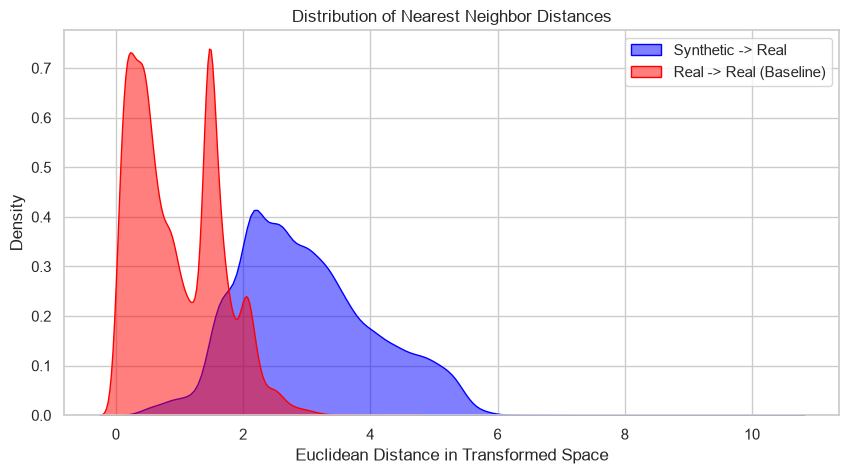

In [5]:
percentiles = [1, 5, 25, 50, 75, 95, 99]
p_syn = np.percentile(d_syn, percentiles)
p_real = np.percentile(d_real, percentiles)

df_percentiles = pd.DataFrame({
    'Percentile': [f'P{p}' for p in percentiles],
    'Synthetic -> Real': p_syn,
    'Real -> Real': p_real
}).set_index('Percentile')

print(df_percentiles.round(4))

plt.figure(figsize=(10, 5))
sns.kdeplot(d_syn, label='Synthetic -> Real', fill=True, color='blue', alpha=0.5)
sns.kdeplot(d_real, label='Real -> Real (Baseline)', fill=True, color='red', alpha=0.5)
plt.title('Distribution of Nearest Neighbor Distances')
plt.xlabel('Euclidean Distance in Transformed Space')
plt.ylabel('Density')
plt.legend()
plt.show()


# 7. High-Similarity Synthetic Records
Let's locate the synthetic records that got the closest to a real record and inspect them safely.

In [6]:
closest_syn_idx = np.argsort(d_syn)[:3]

for rank, idx in enumerate(closest_syn_idx):
    dist = d_syn[idx]
    real_idx = indices_syn[idx][0]
    
    print(f"\n--- Rank {rank+1} Closest Synthetic Record ---")
    print(f"Distance to nearest real record: {dist:.4f}")
    
    # We display side-by-side using a DataFrame for easy viewing
    syn_record = df_syn.iloc[idx].copy()
    syn_record.name = 'Synthetic'
    real_record = df_real.iloc[real_idx].copy()
    real_record.name = 'Nearest Real'
    
    comp_df = pd.concat([syn_record, real_record], axis=1)
    # Highlight differences
    comp_df['Matches?'] = comp_df['Synthetic'] == comp_df['Nearest Real']
    print(comp_df)



--- Rank 1 Closest Synthetic Record ---
Distance to nearest real record: 0.1839
                         Synthetic        Nearest Real  Matches?
age                             36                  36      True
workclass                  Private             Private      True
fnlwgt                      184915              184655     False
education                  HS-grad             HS-grad      True
education-num                    9                   9      True
marital-status  Married-civ-spouse  Married-civ-spouse      True
occupation       Machine-op-inspct   Machine-op-inspct      True
relationship               Husband             Husband      True
race                         White               White      True
sex                           Male                Male      True
capital-gain                   158                   0     False
capital-loss                    34                   0     False
hours-per-week                  50                  48     False
native-co

# 8. Initial Privacy Interpretation
Based on empirical Nearest-Neighbor observations:

- **No Obvious Memorization**: The Gaussian Copula did not \"memorize\" exact copies of real records. The minimum distance from a synthetic point to a real point is `~0.18`. By contrast, in the real data, many records are perfectly identical to other real records (min distance `0.0`), simply due to coincidental demographic overlap in a dataset with 32,561 rows.
- **Synthetic Records are \"Further Away\"**: The mean distance of Synthetic -> Real (`~2.98`) is substantially higher than the Real -> Real baseline (`~0.96`). Looking at the KDE plot, the synthetic data is scattered much more broadly across the feature space.
- **Conclusion**: There is no empirical evidence of 1:1 overfitting or exact record copying. A random synthetic record is significantly further away from a real individual than real individuals are from each other.

# 9. Limitations
- **Not a Formal Guarantee**: This nearest-neighbor heuristic is an intuitive empirical check. It is **not** a formal mathematical privacy guarantee (like Differential Privacy).
- **Other Attack Vectors**: This check does not measure vulnerability to Membership Inference Attacks (MIA), Attribute Inference Attacks, or sophisticated adversarial re-identification vectors.